# Module 2 — DAGs: Confounders, Colliders, Mediators

Part of the Causal Inference Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- The running question: did NSW (National Supported Work), a US job-training program for men with very low earnings, raise the earnings of the men who took it?
- Comparing the men who took the program with men who didn't gives the wrong answer when the two groups were different to begin with. The fix is to compare like with like.
- Module 2 answers the question that comes first: like with like on what? Some differences between the groups must be adjusted for, and some must be left alone. Adjusting for the wrong one can create an effect that isn't there, or hide one that is.
- The tool is a drawing of what causes what, called a DAG (directed acyclic graph). It decides what to adjust for before any number is computed.

**What this module produces:**
1. Three small drawings, one per basic shape, each tested on made-up data where the true answer is known.
2. A drawing for the job-training question, and the list of columns it says to adjust for.
3. Two checks on the real job-training data: what adjusting for the right columns does, and what adjusting for a wrong one does.

## From the curriculum

> ## <u>Module 2 — DAGs: Confounders, Colliders, Mediators</u>
>
> **Concepts**
> - A DAG (directed acyclic graph): a drawing of what causes what. Arrows point
>   from cause to effect, and following the arrows never leads back to where
>   you started.
> - Three shapes:
>   1. Confounder: one thing affects both who gets the treatment and the outcome.
>   2. Mediator: the treatment works through it.
>   3. Collider: both the treatment and the outcome affect it.
> - Adjusting for a column: comparing like with like on it (only men with the
>   same value are compared). Good and bad controls (columns to adjust for or
>   not): adjust for confounders. Don't adjust for a mediator when you want the
>   whole effect, and never for a collider or anything the treatment changed.
> - An unmeasured confounder: a box in the drawing with no column in the data.
>
> **Why it matters**
> "Adjust for everything" is wrong advice. Adjusting for the wrong column can
> create an effect that isn't there, or hide one that is. The drawing decides
> which columns to adjust for, before any number is computed.
>
> **Worked example**
> 1. Three small examples on made-up numbers with a known true effect, one
>    per shape: adjusting helps for the confounder and hurts for the mediator
>    and the collider.
> 2. NSW (National Supported Work) job-training data vs the PSID (Panel Study
>    of Income Dynamics) survey men, real data: adjusting for more and more
>    confounders moves the naive gap (a plain comparison of the two groups),
>    (−$15,204.8), toward the experiment's $1,794.3,
>    until the groups get too small to go further.
> 3. A bad control on the real experiment: keeping only the men who had a job
>    in 1978 shrinks $1,794.3 to $1,340.8.
>
> **Resources**
> - [Causal Inference: The Mixtape, ch. 3 "Directed Acyclic Graphs"](https://mixtape.scunning.com/03-Directed_Acyclical_Graphs.html)
>   (Scott Cunningham, ~45 min, verified): drawing DAGs, confounders, colliders.
> - [The Effect, ch. 8 "Causal Paths and Closing Back Doors"](https://theeffectbook.net/ch-CausalPaths.html)
>   (Nick Huntington-Klein, ~40 min, verified): which columns to adjust for,
>   colliders.
> - [A Crash Course in Good and Bad Controls](https://ftp.cs.ucla.edu/pub/stat_ser/r493.pdf)
>   (Cinelli, Forney & Pearl, ~45 min, verified): which columns to adjust for,
>   case by case.
>
> **Exercise type:** which single column removes the most bias, and is a column
> measured during the program a good control? Fully worked.
>
> **Interview angle:** "Should we control for the number of sessions last week
> when measuring the effect of feature X?"

## Lesson

### What a DAG is

DAG stands for directed acyclic graph. It's a drawing of what causes what:
- Each box is one thing about a person, for example "earnings in 1975".
- An arrow from A to B means "A affects B".
- "Directed": every arrow points one way.
- "Acyclic": following the arrows never brings you back to the box you started from.

The arrows are not computed from data. They're written down from what you know about how the world works. Data can only check whether they look plausible.

### What "adjusting for" a column means

Adjusting for a column means comparing like with like on that column:
1. Split the people into groups that share the same value of the column (for example: men who earned nothing in 1975, and men who earned something).
2. Inside each group, compare the men who took the program with the men who didn't.
3. Average the gaps from step 2, giving each group a weight. For the effect on the men who took the program, each group counts in proportion to how many of them it has.

Inside a group, the column can't explain the gap, because everyone in the group has the same value. This module adjusts with groups, so every step stays visible. Modules 3–5 do the same job with regression, matching and weighting, which can handle many columns at once.

### The three basic shapes

Every drawing, however big, is built from three shapes. T is the treatment (taking the program) and Y is the outcome (earnings after it).

| Shape | Drawing | In words | Adjust for it? |
|---|---|---|---|
| Confounder | T ← C → Y | C affects both who takes the program and earnings after it | **Yes.** Otherwise part of the gap is C, not the program |
| Mediator | T → M → Y | the program works through M | **No**, when you want the program's whole effect. Adjusting removes the part that goes through M |
| Collider | T → K ← Y | both the program and earnings affect K | **No.** Adjusting creates a link between T and Y that isn't there |

The worked example below tests each row on made-up data where the true effect is known.

## Worked example 1: the three shapes on made-up data

**Chosen example** (not data), because only made-up numbers have a known true effect to check against. Every number in each setup is chosen. Earnings are in $ thousands.

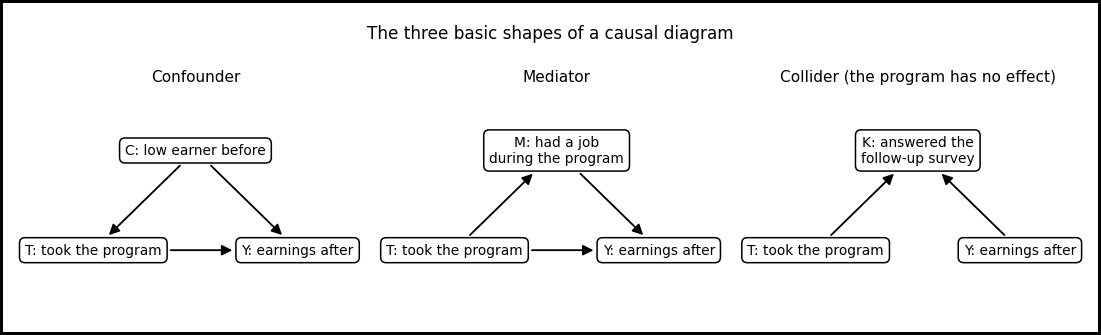

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common
from common import show, draw_dag, BLUE, ORANGE, GREY

GREEN, RED = "#1a7f37", "#cf222e"
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
pos3 = {"T: took the program": (0, 0), "Y: earnings after": (3.4, 0)}
draw_dag(axes[0], {**pos3, "C: low earner before": (1.7, 1)},
         [("C: low earner before", "T: took the program"), ("C: low earner before", "Y: earnings after"),
          ("T: took the program", "Y: earnings after")], "Confounder")
draw_dag(axes[1], {**pos3, "M: had a job\nduring the program": (1.7, 1)},
         [("T: took the program", "M: had a job\nduring the program"), ("M: had a job\nduring the program", "Y: earnings after"),
          ("T: took the program", "Y: earnings after")], "Mediator")
draw_dag(axes[2], {**pos3, "K: answered the\nfollow-up survey": (1.7, 1)},
         [("T: took the program", "K: answered the\nfollow-up survey"), ("Y: earnings after", "K: answered the\nfollow-up survey")],
         "Collider (the program has no effect)")
fig.suptitle("The three basic shapes of a causal diagram", fontsize=11)
plt.tight_layout()
plt.show()

### Shape 1: the confounder

**The setup:** half the men were low earners before the program. Low earners take the program more often (80% of them, against 20% of the others), and earn 6 less afterwards whether they take it or not. The program itself adds +2 for everyone who takes it.

**The motive:** this tests the first row of the three-shapes table. A plain comparison should miss the true +2, because most of the men who took the program are low earners, who earn 6 less anyway. Comparing only men with the same status should remove that 6 and find the +2.

**How each line is calculated:** every man starts with earnings of 10. He gets +2 if he took the program and −6 if he is a low earner. Half of all men (50%) are low earners.

**Naive gap** = (mean earnings of the men who took the program) − (mean earnings of the men who did not take it)

Why: this is the comparison anyone would make first. It should miss the true +2.

1. Mean earnings of the men who took the program
   - Low earners who took it = 50% × 80% = 40% of all men, others who took it = 50% × 20% = 10% of all men, everyone who took it = 40% + 10% = 50% of all men
   - Mean = (10 × 100%) + (2 × 100%) + (−6 × (40% / 50%)) = 7.2
2. Mean earnings of the men who did not take it
   - Low earners who did not take it = 50% × 20% = 10% of all men, others who did not take it = 50% × 80% = 40% of all men, everyone who did not take it = 10% + 40% = 50% of all men
   - Mean = (10 × 100%) + (2 × 0%) + (−6 × (10% / 50%)) = 8.8
3. Naive gap = 7.2 − 8.8 = −1.6

**Gap among low earners** = (mean earnings of the low earners who took the program) − (mean earnings of the low earners who did not take it)

Why: comparing only low earners puts the −6 on both sides, so it drops out and only the program is left.

1. Mean earnings of the low earners who took the program
   - Low earners who took it = 50% × 80% = 40% of all men
   - Mean = (10 × 100%) + (2 × 100%) + (−6 × (40% / 40%)) = 6
2. Mean earnings of the low earners who did not take it
   - Low earners who did not take it = 50% × 20% = 10% of all men
   - Mean = (10 × 100%) + (2 × 0%) + (−6 × (10% / 10%)) = 4
3. Gap among low earners = 6 − 4 = 2

**Gap among the others** = (mean earnings of the others who took the program) − (mean earnings of the others who did not take it)

Why: the same comparison among the men who were not low earners. Nobody on either side has the −6.

1. Mean earnings of the others who took the program
   - Others who took it = 50% × 20% = 10% of all men
   - Mean = (10 × 100%) + (2 × 100%) + (−6 × (0% / 10%)) = 12
2. Mean earnings of the others who did not take it
   - Others who did not take it = 50% × 80% = 40% of all men
   - Mean = (10 × 100%) + (2 × 0%) + (−6 × (0% / 40%)) = 10
3. Gap among the others = 12 − 10 = 2

**Adjusted gap** = (gap among low earners × low earners' share of the men who took the program) + (gap among the others × the others' share of the men who took the program)

Why: this turns the two gaps into one number, to check against the true +2. We want the effect on the men who took the program, so each group counts by its share of them.

- Low earners' share of the men who took the program = 40% / 50% = 80%, the others' share = 10% / 50% = 20%
- Adjusted gap = (2 × 80%) + (2 × 20%) = 2

**Observation:** without adjusting, the program looks harmful: (−1.6), even though it adds +2. Adjusting for "low earner before" gives 2, exactly the true +2.

In words: the men who took the program were mostly low earners, who earn 6 less anyway. The plain comparison mixes that 6 into the program's effect. Inside each group, everyone has the same "low earner before" status, so only the program is left to explain the gap.

### Shape 2: the mediator

**The setup:** a coin flip decides who takes the program, so the groups start out alike: 50% of all men take it. The program helps in two ways: directly (+1), and by raising the chance of having a job during the program from 40% to 70%. A job adds +5. So the program's whole effect is the direct +1, plus +5 for the extra 30% of men who got a job: (1 × 100%) + (5 × 30%) = +2.5.

**The motive:** this tests the second row of the three-shapes table. The plain comparison should already find the whole +2.5, because the coin flip made the groups alike. Adjusting for the job should cut it to the direct +1, because comparing men with the same job status throws out the part that works through the job.

**How each line is calculated:** every man starts with earnings of 10. He gets +1 if he took the program and +5 if he had a job during the program.

**Naive gap** = (mean earnings of the men who took the program) − (mean earnings of the men who did not take it)

Why: this is the plain comparison. Here it should find the whole effect, +2.5.

1. Mean earnings of the men who took the program
   - Took it and had a job = 50% × 70% = 35% of all men, took it and had no job = 50% × 30% = 15% of all men, everyone who took it = 35% + 15% = 50% of all men
   - Mean = (10 × 100%) + (1 × 100%) + (5 × (35% / 50%)) = 14.5
2. Mean earnings of the men who did not take it
   - Did not take it and had a job = 50% × 40% = 20% of all men, did not take it and had no job = 50% × 60% = 30% of all men, everyone who did not take it = 20% + 30% = 50% of all men
   - Mean = (10 × 100%) + (1 × 0%) + (5 × (20% / 50%)) = 12
3. Naive gap = 14.5 − 12 = 2.5

**Gap among men with a job** = (mean earnings of the men with a job who took the program) − (mean earnings of the men with a job who did not take it)

Why: comparing only men with a job puts the +5 on both sides, so it drops out, and with it the part of the program that works through the job.

1. Mean earnings of the men with a job who took the program
   - Took it and had a job = 50% × 70% = 35% of all men
   - Mean = (10 × 100%) + (1 × 100%) + (5 × (35% / 35%)) = 16
2. Mean earnings of the men with a job who did not take it
   - Did not take it and had a job = 50% × 40% = 20% of all men
   - Mean = (10 × 100%) + (1 × 0%) + (5 × (20% / 20%)) = 15
3. Gap among men with a job = 16 − 15 = 1

**Gap among men without a job** = (mean earnings of the men without a job who took the program) − (mean earnings of the men without a job who did not take it)

Why: the same comparison among men without a job. Nobody on either side has the +5.

1. Mean earnings of the men without a job who took the program
   - Took it and had no job = 50% × 30% = 15% of all men
   - Mean = (10 × 100%) + (1 × 100%) + (5 × (0% / 15%)) = 11
2. Mean earnings of the men without a job who did not take it
   - Did not take it and had no job = 50% × 60% = 30% of all men
   - Mean = (10 × 100%) + (1 × 0%) + (5 × (0% / 30%)) = 10
3. Gap among men without a job = 11 − 10 = 1

**Adjusted gap** = (gap among men with a job × men with a job's share of the men who took the program) + (gap among men without a job × men without a job's share of the men who took the program)

Why: this turns the two gaps into one number, to check against the whole +2.5. We want the effect on the men who took the program, so each group counts by its share of them.

- Men with a job's share of the men who took the program = 35% / 50% = 70%, men without a job's share = 15% / 50% = 30%
- Adjusted gap = (1 × 70%) + (1 × 30%) = 1

**Observation:** without adjusting, the gap is 2.5, exactly the true whole effect. Adjusting for the job gives 1 in both groups, and 1 overall: only the direct part, +1.

In words: getting men into jobs was one of the ways the program helped. Comparing only men who all had a job (or all didn't) throws that way out. Here the plain comparison is the right one, because the coin flip already made the groups alike.

### Shape 3: the collider

**The setup:** a coin flip decides who takes the program: 50% of all men take it. The program has **no effect** on earnings. Half of all men (50%) are high earners, whether they take the program or not. A year later, a follow-up survey is sent to everyone. Men who took the program answer more often (they feel connected to it), and so do high earners (they're happy to report). The chance of answering is 100% for high earners who took the program, 60% for the others who took it, 60% for high earners who did not take it, and 20% for the others who did not take it. The analyst only has data on the men who answered.

**The motive:** this tests the third row of the three-shapes table. Across all men, the plain comparison should find the true 0. Looking only at the men who answered should create a gap the program never caused.

**How each line is calculated:** every man starts with earnings of 8. He gets +0 if he took the program, because it has no effect, and +4 if he is a high earner.

**Naive gap** = (mean earnings of the men who took the program) − (mean earnings of the men who did not take it)

Why: this is the plain comparison, on everyone. It should find the true 0.

1. Mean earnings of the men who took the program
   - High earners who took it = 50% × 50% = 25% of all men, others who took it = 50% × 50% = 25% of all men, everyone who took it = 25% + 25% = 50% of all men
   - Mean = (8 × 100%) + (0 × 100%) + (4 × (25% / 50%)) = 10
2. Mean earnings of the men who did not take it
   - High earners who did not take it = 50% × 50% = 25% of all men, others who did not take it = 50% × 50% = 25% of all men, everyone who did not take it = 25% + 25% = 50% of all men
   - Mean = (8 × 100%) + (0 × 0%) + (4 × (25% / 50%)) = 10
3. Naive gap = 10 − 10 = 0

**Gap among the men who answered** = (mean earnings of the men who answered and took the program) − (mean earnings of the men who answered and did not take it)

Why: the analyst only has the men who answered, so this is the gap the analyst sees. It should show a gap the program never caused.

1. Mean earnings of the men who answered and took the program
   - High earners who took it and answered = 25% × 100% = 25% of all men, others who took it and answered = 25% × 60% = 15% of all men, everyone who took it and answered = 25% + 15% = 40% of all men
   - Mean = (8 × 100%) + (0 × 100%) + (4 × (25% / 40%)) = 10.5
2. Mean earnings of the men who answered and did not take it
   - High earners who did not take it and answered = 25% × 60% = 15% of all men, others who did not take it and answered = 25% × 20% = 5% of all men, everyone who did not take it and answered = 15% + 5% = 20% of all men
   - Mean = (8 × 100%) + (0 × 0%) + (4 × (15% / 20%)) = 11
3. Gap among the men who answered = 10.5 − 11 = −0.5

Note: there are only two calculations here, not three as in Shapes 1 and 2. The analyst only has data on the men who answered, so there's one group to compare in, and no gaps to average.

**Observation:** across all men the gap is 0, exactly the true 0. Among the men who answered the survey, it's (−0.5): the program now looks harmful.

In words: a man who didn't take the program needed another reason to answer, and the other reason was higher earnings. So among the men who answered, the ones without the program are richer on average. Looking only at the men who answered is adjusting for a collider, and it creates a gap the program never caused.

**Conclusion (on made-up data with a known truth):**
- Confounder: adjusting fixed the answer.
- Mediator: adjusting broke an answer that was already right, by missing part of an effect that was there.
- Collider: adjusting broke an answer that was already right, by finding an effect that wasn't there.

## Worked example 2: the drawing for the job-training data

**The data, again:** the 185 men who took NSW, compared with 2,490 men from the PSID (Panel Study of Income Dynamics), a US household survey of men who never applied to the program. The men in this data took the program in 1976 or 1977, for up to 12 months of training. So 1974 and 1975 earnings are from before it, 1977 is during it, and 1978 is after it.

The same data also has a lottery experiment: 260 men who applied but were kept out by a lottery (the randomized controls). The experiment's answer, $1,794.3, is our best benchmark: an estimate with its own uncertainty, but free of selection bias.

**The drawing:** each "before" column can affect both who took the program and earnings in 1978. Motivation probably does too, but no column measures it, so it gets a dashed box.

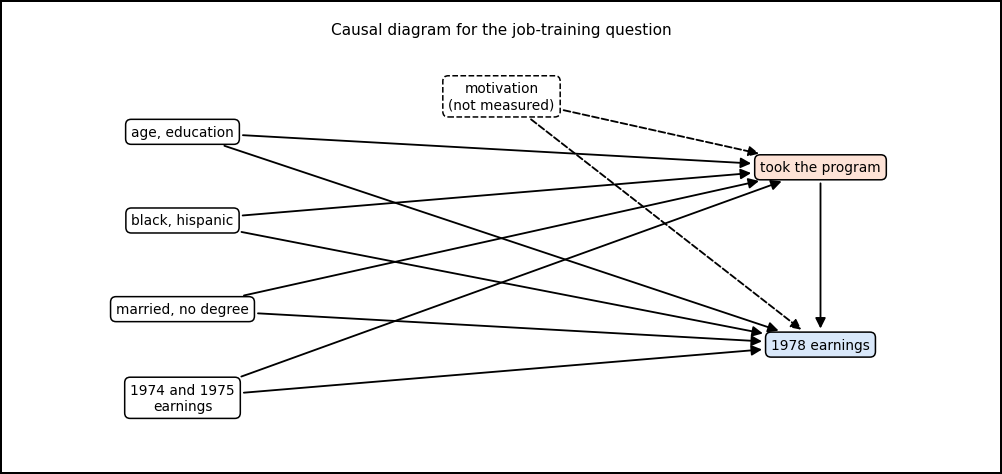

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.2))
nodes = {"age, education": (0, 2), "black, hispanic": (0, 1), "married, no degree": (0, 0),
         "1974 and 1975\nearnings": (0, -1), "motivation\n(not measured)": (1.6, 2.4),
         "took the program": (3.2, 1.6), "1978 earnings": (3.2, -0.4)}
before = ["age, education", "black, hispanic", "married, no degree", "1974 and 1975\nearnings", "motivation\n(not measured)"]
edges = [(b, t) for b in before for t in ("took the program", "1978 earnings")] + [("took the program", "1978 earnings")]
draw_dag(ax, nodes, edges, "Causal diagram for the job-training question",
         dashed=("motivation\n(not measured)",), colors={"took the program": "#fde2d6", "1978 earnings": "#d9e8fa"})
plt.tight_layout()
plt.show()

**What the drawing says:**
- A "before" column is a confounder when it affects both who took the program and 1978 earnings. In the drawing, every "before" box has both arrows, so every one is a confounder.
- The list of columns to adjust for: age, years of education, black, hispanic, married, no degree, 1974 earnings and 1975 earnings.
- None of them can be a mediator: they were all measured before the program started, so the program couldn't have changed them.
- Motivation is also a confounder, and it can't be adjusted for, because no column measures it. Module 10 measures how much an unmeasured confounder like this could change the answer.

### Do the data back the arrows?

The drawing comes from judgment, but the data can check each confounder's two arrows:
1. The arrow from the column into "took the program": do the treated men and the PSID men differ on the column?
2. The arrow from the column into "1978 earnings": among the PSID men, does the column move together with 1978 earnings? The PSID men are used because they never took the program, so its effect isn't mixed into their 1978 earnings. In the treated men, it is. The number used is the correlation: it runs from (−1) to 1, and 0 means the two columns don't move together at all.

In [3]:
exp = common.load_lalonde("experimental")
psid = common.load_lalonde("psid")
nsw_t = exp[exp.treat == 1].copy()
nsw_c = exp[exp.treat == 0].copy()
psid_c = psid[psid.treat == 0].copy()

cols = {"age": "age", "education": "years of education", "black": "black (share)", "hispanic": "hispanic (share)",
        "married": "married (share)", "nodegree": "no degree (share)", "re74": "1974 earnings", "re75": "1975 earnings"}
fmt = {"age": "{:.1f}", "education": "{:.1f}", "re74": "{:,.1f}", "re75": "{:,.1f}"}
show(pd.DataFrame({
    "before the program": list(cols.values()),
    f"treated men ({len(nsw_t)} men)": [fmt.get(c, "{:.3f}").format(nsw_t[c].mean()) for c in cols],
    f"PSID men ({len(psid_c):,} men)": [fmt.get(c, "{:.3f}").format(psid_c[c].mean()) for c in cols],
    f"correlation with 1978 earnings: PSID men ({len(psid_c):,} men)": [f"{np.corrcoef(psid_c[c], psid_c.re78)[0, 1]:.3f}" for c in cols],
}))

before the program  treated men (185 men)  PSID men (2,490 men)  correlation with 1978 earnings: PSID men (2,490 men)
age                                  25.8                  34.9                                                 0.055
years of education                   10.3                  12.1                                                 0.354
black (share)                       0.843                 0.251                                                -0.211
hispanic (share)                    0.059                 0.033                                                -0.005
married (share)                     0.189                 0.866                                                 0.132
no degree (share)                   0.708                 0.305                                                -0.264
1974 earnings                     2,095.6              19,428.7                                                 0.689
1975 earnings                     1,532.1              1

**Observation:**
- Arrow 1: the biggest differences are on 1974 and 1975 earnings (in 1975: $19,063.3 for the PSID men vs $1,532.1 for the treated men) and on married (0.866 vs 0.189).
- Arrow 2: 1975 and 1974 earnings move most closely with 1978 earnings (0.731 and 0.689). Education, no degree and black come next. Age and hispanic barely move with it (0.055 and (−0.005)).

**Hypothesis:** the earnings columns are the strongest confounders, because they're strong on both arrows. Correlation alone can't prove an arrow, so this stays a hypothesis. The next part tests it by adjusting.

## Worked example 3: adjusting for confounders, on the real data

Now adjust, one confounder at a time, and watch the gap move.

**How the groups are averaged:** the question is about the men who took the program (the ATT, average treatment effect on the treated). So each group's gap counts in proportion to how many **treated** men are in it.

### Step 1: adjusting for one confounder, zero 1975 earnings

Why this one first: 1975 earnings move most closely with 1978 earnings (0.731), so it's the strongest confounder. Adjusting with groups needs a yes/no column, and zero vs some is the simplest yes/no split of 1975 earnings.

In [4]:
def adjusted_gap(columns):
    """Split both groups by the given yes/no columns, compare inside each group, average by treated men."""
    rows = []
    for key, g_t in nsw_t.groupby(columns):
        g_c = psid_c
        for c, v in zip(columns, key if isinstance(key, tuple) else (key,)):
            g_c = g_c[g_c[c] == v]
        rows.append({"treated men": len(g_t), "PSID men": len(g_c),
                     "treated: mean 1978 earnings": g_t.re78.mean(), "PSID: mean 1978 earnings": g_c.re78.mean()})
    rows = pd.DataFrame(rows)
    rows["gap"] = rows["treated: mean 1978 earnings"] - rows["PSID: mean 1978 earnings"]
    estimate = (rows["gap"] * rows["treated men"]).sum() / rows["treated men"].sum()
    return rows, estimate

for d in (nsw_t, psid_c):
    d["zero75"] = (d.re75 == 0).astype(int)

naive = nsw_t.re78.mean() - psid_c.re78.mean()
print(f"Naive gap = (mean 1978 earnings of the treated men, {len(nsw_t)} men) - (mean 1978 earnings of the PSID men, {len(psid_c):,} men) = {nsw_t.re78.mean():,.1f} - {psid_c.re78.mean():,.1f} = {naive:,.1f}")
print()
rows, est1 = adjusted_gap(["zero75"])
rows.insert(0, "group", ["some 1975 earnings", "zero 1975 earnings"])
show(rows.assign(**{c: rows[c].map("{:,.1f}".format) for c in ["treated: mean 1978 earnings", "PSID: mean 1978 earnings", "gap"]}))
print()
g = rows["gap"].tolist()
k = rows["treated men"].tolist()
print(f"Share of the treated men with some 1975 earnings = {k[0]} / {sum(k)} = {k[0] / sum(k):.1%}, share with zero 1975 earnings = {k[1]} / {sum(k)} = {k[1] / sum(k):.1%}")
print(f"Adjusted gap = (gap among men with some 1975 earnings × their share of the treated men) + (gap among men with zero 1975 earnings × their share of the treated men) = ({g[0]:,.1f} × {k[0] / sum(k):.1%}) + ({g[1]:,.1f} × {k[1] / sum(k):.1%}) = {est1:,.1f}")

Naive gap = (mean 1978 earnings of the treated men, 185 men) - (mean 1978 earnings of the PSID men, 2,490 men) = 6,349.1 - 21,553.9 = -15,204.8

group               treated men  PSID men  treated: mean 1978 earnings  PSID: mean 1978 earnings        gap
some 1975 earnings           74      2241                      6,982.0                  23,345.9  -16,363.9
zero 1975 earnings          111       249                      5,927.2                   5,425.8      501.4

Share of the treated men with some 1975 earnings = 74 / 185 = 40.0%, share with zero 1975 earnings = 111 / 185 = 60.0%
Adjusted gap = (gap among men with some 1975 earnings × their share of the treated men) + (gap among men with zero 1975 earnings × their share of the treated men) = (-16,363.9 × 40.0%) + (501.4 × 60.0%) = -6,244.7


**Observation:** adjusting for one confounder moves the gap from (−$15,204.8) to (−$6,244.7). Among men with zero 1975 earnings, the treated men even earn $501.4 more.

In words: most of the naive gap came from comparing men who earned nothing in 1975 with men who mostly earned a lot. Comparing within each group removes that part.

### Step 2: adding more confounders

Next, adjust for zero 1975 earnings and married together (4 groups), then add black (8 groups).

Why these two: they're yes/no columns where the two groups differ a lot (married 0.189 vs 0.866, black 0.843 vs 0.251). Other confounders, like 1974 earnings, would also move the estimate. Which one comes next is a choice, not a ranking. The change a column adds depends on what's already adjusted for, so no order is the right one. This step is here to watch the estimate move as confounders are added.

In [5]:
rows2, est2 = adjusted_gap(["zero75", "married"])
rows3, est3 = adjusted_gap(["zero75", "married", "black"])
benchmark = common.BENCHMARK_ATT
steps = pd.DataFrame({
    "adjusted for": ["nothing (naive)", "zero 1975 earnings", "+ married", "+ black", "experiment's answer (the benchmark)"],
    "groups": ["1", "2", "4", "8", "—"],
    "change added by this step": ["—"] + [f"{round(b, 1) - round(a, 1):+,.1f}" for a, b in ((naive, est1), (est1, est2), (est2, est3))] + ["—"],
    "total estimate of the effect on the treated men (185 men)": [f"{v:,.1f}" for v in (naive, est1, est2, est3, benchmark)],
})
show(steps)
print()
few_t = rows3.loc[rows3["treated men"].idxmin()]
few_p = rows3.loc[rows3["PSID men"].idxmin()]
print("Why stop at 3 confounders: some of the 8 groups are already very small")
print(f"Group with the fewest treated men = {int(few_t['treated men'])} treated men (and {int(few_t['PSID men'])} PSID men): its gap rests on just {int(few_t['treated men'])} men")
print(f"Group with the fewest PSID men = {int(few_p['PSID men'])} PSID men (and {int(few_p['treated men'])} treated men): {int(few_p['treated men'])} treated men are compared with just {int(few_p['PSID men'])}")

adjusted for                         groups  change added by this step  total estimate of the effect on the treated men (185 men)
nothing (naive)                           1                          —                                                  -15,204.8
zero 1975 earnings                        2                   +8,960.1                                                   -6,244.7
+ married                                 4                   +1,843.7                                                   -4,401.0
+ black                                   8                   +2,443.8                                                   -1,957.2
experiment's answer (the benchmark)       —                          —                                                    1,794.3

Why stop at 3 confounders: some of the 8 groups are already very small
Group with the fewest treated men = 2 treated men (and 173 PSID men): its gap rests on just 2 men
Group with the fewest PSID men = 14 PSID men (and 

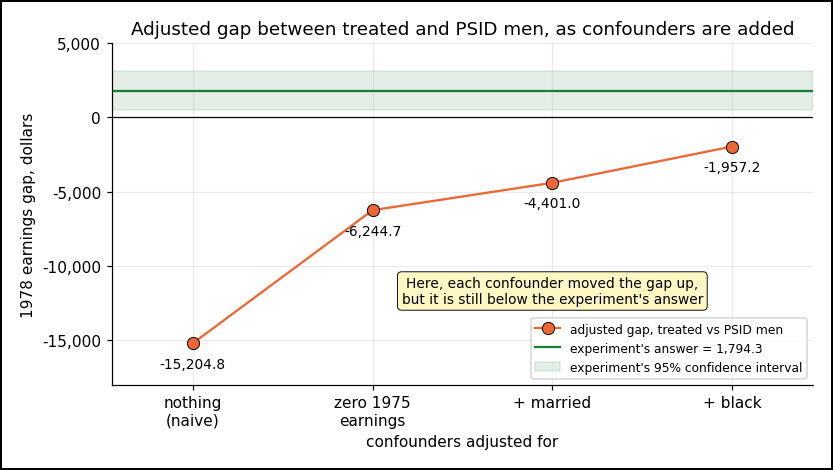

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
labels = ["nothing\n(naive)", "zero 1975\nearnings", "+ married", "+ black"]
vals = [naive, est1, est2, est3]
ax.plot(range(4), vals, "-o", color=ORANGE, ms=8, mec="black", mew=0.6, label="adjusted gap, treated vs PSID men")
for i, v in enumerate(vals):
    ax.text(i, v - 900, f"{v:,.1f}", ha="center", va="top", fontsize=9)
ax.axhline(benchmark, color=GREEN, lw=1.5, label=f"experiment's answer = {benchmark:,.1f}")
se = np.sqrt(nsw_t.re78.var() / len(nsw_t) + nsw_c.re78.var() / len(nsw_c))
ax.axhspan(benchmark - 1.96 * se, benchmark + 1.96 * se, color=GREEN, alpha=0.12, label="experiment's 95% confidence interval")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(4), labels)
ax.set_xlim(-0.45, 3.45)
ax.set_ylim(-18000, 5000)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_ylabel("1978 earnings gap, dollars")
ax.set_xlabel("confounders adjusted for")
ax.set_title("Adjusted gap between treated and PSID men, as confounders are added")
ax.legend(loc="lower right", fontsize=8)
ax.text(2.0, -12500, "Here, each confounder moved the gap up,\nbut it is still below the experiment's answer",
        ha="center", fontsize=9, bbox=dict(boxstyle="round", fc="#fff8c4", ec="black", lw=0.6))
plt.tight_layout()
plt.show()

**Observation:**
- Here, each confounder adjusted for moved the gap closer to the experiment's $1,794.3: (−$15,204.8), then (−$6,244.7), (−$4,401.0) and (−$1,957.2). That isn't a rule: a confounder can move the estimate either way.
- With 3 confounders, the gap still has the wrong sign.
- It's also outside the experiment's 95% band ($479.2 to $3,109.5). The experiment's own uncertainty can't explain that distance, so bias is still left in the estimate. This is a strong hint, not proof, because the estimate has its own uncertainty too, which the chart doesn't show.
- With 3 confounders, the 8 groups are already very uneven: one has only 2 treated men, and another has 82 treated men but only 14 PSID men to compare with.
- Estimates from groups this small carry a lot of uncertainty of their own.

**Conclusion:** comparing inside groups runs out of men long before all 8 "before" columns in the table are used. Adjusting for many columns at once needs the methods of Modules 3–5.

**Hypothesis:** the remaining gap comes from the confounders not yet adjusted for (age, education, hispanic, no degree and 1974 earnings), from 1975 earnings being split only into zero vs some, not by amount, and from motivation, which no column measures.

## Worked example 4: a bad control, on the real experiment

Now the opposite mistake, on the lottery data, where the answer to compare with is the benchmark, $1,794.3.

Here the comparison is between the 185 treated men and the 260 men kept out by the lottery (the randomized controls). A column that sounds harmless: "had any earnings in 1978", meaning had a job at some point in 1978. Suppose an analyst decides to compare only men who had a job, "to compare like with like".

The problem: the program itself changed who had a job. That makes it a column the program affected, not a "before" column.

In [7]:
job_t = nsw_t.re78 > 0
job_c = nsw_c.re78 > 0
print(f"Share with any 1978 earnings, treated men ({len(nsw_t)} men) = {job_t.mean():.1%}")
print(f"Share with any 1978 earnings, randomized controls ({len(nsw_c)} men) = {job_c.mean():.1%}")
print()
print(f"ATT, all men = (mean 1978 earnings of the treated men, {len(nsw_t)} men) - (mean 1978 earnings of the randomized controls, {len(nsw_c)} men) = "
      f"{nsw_t.re78.mean():,.1f} - {nsw_c.re78.mean():,.1f} = {nsw_t.re78.mean() - nsw_c.re78.mean():,.1f}")
gap_job = nsw_t.re78[job_t].mean() - nsw_c.re78[job_c].mean()
print(f"Gap, only men with a job = (mean 1978 earnings of the treated men with a job, {job_t.sum()} men) - (mean 1978 earnings of the randomized controls with a job, {job_c.sum()} men) = "
      f"{nsw_t.re78[job_t].mean():,.1f} - {nsw_c.re78[job_c].mean():,.1f} = {gap_job:,.1f}")

Share with any 1978 earnings, treated men (185 men) = 75.7%
Share with any 1978 earnings, randomized controls (260 men) = 64.6%

ATT, all men = (mean 1978 earnings of the treated men, 185 men) - (mean 1978 earnings of the randomized controls, 260 men) = 6,349.1 - 4,554.8 = 1,794.3
Gap, only men with a job = (mean 1978 earnings of the treated men with a job, 140 men) - (mean 1978 earnings of the randomized controls with a job, 168 men) = 8,389.9 - 7,049.1 = 1,340.8


**Observation:** the program raised the share of men with a job from 64.6% to 75.7%. Keeping only men with a job shrinks the gap from $1,794.3 to $1,340.8.

Why it shrinks, even though men with a job earn more: a man with no job has 1978 earnings of 0. Removing the zeros raises both groups' means, and it raises the controls' mean more, because more of them were zeros:
- Mean of the treated men = (8,389.9 × (140 / 185)) + (0 × (45 / 185)) = 6,349.1
- Mean of the randomized controls = (7,049.1 × (168 / 260)) + (0 × (92 / 260)) = 4,554.8

In words, two things go wrong at once:
1. Getting men into a job was part of what the program did. Keeping only men with a job throws that part away, as the mediator did in Worked example 1.
2. "Had a job" is also a collider, at the same time. A shape isn't a label on a box but a pattern of arrows around it, and one box can sit in two patterns. A more motivated man is more likely to have a job, and also earns more, so two arrows point into "had a job": program → had a job ← motivation → 1978 earnings. Keeping only men with a job changes who is left in each group: among the men with a job, those without the program needed more motivation to get one.

**Conclusion:** a column the program changed is never safe to adjust for, even when it sounds like "comparing like with like". A column fixed before the program is safe only if it isn't a collider, i.e. it isn't the result of both what makes men join the program and what makes them earn.

## Good and bad controls: the summary

| The column... | Example | Adjust for it? |
|---|---|---|
| affects both who takes the program (T) and the outcome (Y): a confounder, T ← C → Y | 1975 earnings | **Yes** |
| affects only the outcome (Y) | a column that changes earnings but not who takes the program | Optional: it doesn't remove bias, but it can make the estimate less noisy |
| affects only who takes the program (T) | for example, how far a man lived from the program office, if that changed whether he joined but not his earnings | **No**: it doesn't remove bias, and it makes the estimate noisier |
| is affected by the program (T) and affects the outcome (Y): a mediator, T → M → Y | had a job in 1978 | **No** |
| is affected by both the program (T) and the outcome (Y): a collider, T → K ← Y | answered the follow-up survey | **No** |
| affects both who takes the program (T) and the outcome (Y), but no column measures it: an unmeasured confounder | motivation | Can't adjust: name it as a threat |

## Exercise — which single confounder removes the most bias?

Adjust the naive gap for one column at a time, using the same method as Worked example 3:
1. "no degree"
2. "black"

Compare both with the result for "zero 1975 earnings", (−$6,244.7). Which single column removes the most bias, and why?

Then a second question: a colleague suggests also adjusting for "had a job in 1977", which is during the program. Good control or bad?

Write your answers first, then run the next cell.

In [8]:
rows_nd, est_nd = adjusted_gap(["nodegree"])
rows_bl, est_bl = adjusted_gap(["black"])
show(pd.DataFrame({
    "column": ["no degree", "black", "zero 1975 earnings"],
    f"share: treated men ({len(nsw_t)} men)": [f"{nsw_t[c].mean():.3f}" for c in ("nodegree", "black", "zero75")],
    f"share: PSID men ({len(psid_c):,} men)": [f"{psid_c[c].mean():.3f}" for c in ("nodegree", "black", "zero75")],
    f"correlation with 1978 earnings: PSID men ({len(psid_c):,} men)":
        [f"{np.corrcoef(psid_c[c], psid_c.re78)[0, 1]:.3f}" for c in ("nodegree", "black", "zero75")],
    "adjusted estimate (185 treated men)": [f"{v:,.1f}" for v in (est_nd, est_bl, est1)],
}))
print()
labels = {"no degree": (rows_nd, est_nd, "with a degree", "with no degree"),
          "black": (rows_bl, est_bl, "who are not black", "who are black"),
          "zero 1975 earnings": (rows, est1, "with some 1975 earnings", "with zero 1975 earnings")}
for name, (r, est, lab0, lab1) in labels.items():
    k, n = r["treated men"], r["treated men"].sum()
    print(f"Adjusted estimate, {name} =\n    = (gap among men {lab0} × their share of the treated men) + (gap among men {lab1} × their share of the treated men) =\n    = "
          f"({r['gap'][0]:,.1f} × ({k[0]} / {n})) + ({r['gap'][1]:,.1f} × ({k[1]} / {n})) = {est:,.1f}")
    print()
dist = benchmark - naive
print(f"Distance from the naive gap to the benchmark = (benchmark) - (naive gap) = {benchmark:,.1f} - ({naive:,.1f}) = {dist:,.1f}")
print()
for name, v in [("no degree", est_nd), ("black", est_bl), ("zero 1975 earnings", est1)]:
    print(f"Share of that distance closed, {name} = ((adjusted estimate) - (naive gap)) / (distance) = ({v:,.1f} - ({naive:,.1f})) / {dist:,.1f} = {(v - naive) / dist:.1%}")

column              share: treated men (185 men)  share: PSID men (2,490 men)  correlation with 1978 earnings: PSID men (2,490 men)  adjusted estimate (185 treated men)
no degree                                  0.708                        0.305                                                -0.264                            -11,607.6
black                                      0.843                        0.251                                                -0.211                            -10,709.5
zero 1975 earnings                         0.600                        0.100                                                -0.346                             -6,244.7

Adjusted estimate, no degree =
    = (gap among men with a degree × their share of the treated men) + (gap among men with no degree × their share of the treated men) =
    = (-16,232.6 × (54 / 185)) + (-9,701.2 × (131 / 185)) = -11,607.6

Adjusted estimate, black =
    = (gap among men who are not black × their share of t

**Answer:**
1. "No degree" moves the gap to (−$11,607.6) and closes 21.2% of the distance to the benchmark. "Black" moves it to (−$10,709.5) and closes 26.4%. "Zero 1975 earnings" moves it furthest, to (−$6,244.7), closing 52.7%.
2. Why: "zero 1975 earnings" moves most closely with 1978 earnings: (−0.346), against (−0.264) for no degree and (−0.211) for black. How closely is the size of the correlation, ignoring its sign. The minus only says that more of the column goes with lower 1978 earnings. It isn't the column where the groups differ most: black differs more (0.843 vs 0.251, against 0.600 vs 0.100). How much bias a column removes depends on both arrows together, so no single number in the table ranks the columns: only adjusting shows it.
3. "Had a job in 1977" is a **bad** control. 1977 is during the program, so the program could have changed it, just like "had a job in 1978" in Worked example 4.

## Interview angle

> "We want to know whether feature X makes users keep using the app. Should we control for the number of sessions last week?"

A strong answer depends on when "last week" is:
- If it's the week before the user got feature X, it's a confounder, like "low earner before" in Shape 1. Keen users use the app more, so they're more likely to try feature X, and also more likely to keep using the app anyway. Without adjusting for it, part of their staying is credited to feature X. Adjust for it.
- If it's the week after, feature X may have raised it, so it's a mediator, like the job in Shape 2. Feature X brings users back more often, and that's part of how it keeps them. Comparing users with the same number of sessions throws that part away. Don't adjust for it.
- Then say what can't be adjusted for: how keen a user is, beyond what the columns measure, is an unmeasured confounder.

## Key takeaways

- A DAG is a drawing of what causes what. The arrows come from judgment about the world, and data can only check that they're plausible.
- Adjust for confounders. On made-up data, adjusting for a confounder turned (−1.6) into 2, the true effect.
- Don't adjust for a mediator when you want the whole effect, and never for a collider. On made-up data, adjusting for a mediator cut a true 2.5 to 1, and adjusting for a collider turned a true 0 into (−0.5).
- A column the treatment changed is never safe. On the real experiment, keeping only men with a job in 1978 shrank $1,794.3 to $1,340.8.
- On the real job-training data, adjusting for 3 confounders moved the naive gap of (−$15,204.8) to (−$1,957.2). But one group was already down to 2 treated men, so more columns need regression, matching or weighting (Modules 3–5).
- Unmeasured confounders stay a threat. Motivation has a box in the drawing, but no column in the data.